In [ ]:
!unzip archive.zip

Archive:  archive.zip
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep10_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep1_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep2_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep3_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep4_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep5_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep6_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep7_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep8_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep9_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_002_rep1_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_002_rep2_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_002_rep3_label1.npy  
  inflating: pr

In [ ]:
path = "/content/processed_repetitions/2d_joints/Ex5"

In [ ]:
import subprocess, sys
for pkg in ("optuna",):
    try:
        __import__(pkg)
    except ModuleNotFoundError:
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
        except Exception:
            pass
import os, re, warnings
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display
from collections import defaultdict
from dataclasses import dataclass

import optuna
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.metrics import (matthews_corrcoef, roc_auc_score, roc_curve,
                             confusion_matrix, precision_score)
from sklearn.model_selection import train_test_split
from scipy.signal import savgol_filter

warnings.filterwarnings("ignore")

SEED      = 42
N_TRIALS  = 40
SAVE_PATH = os.getcwd()

def set_seed(s):
    np.random.seed(s)

set_seed(SEED)

In [ ]:
FNAME_RE = re.compile(r"PM_(\w+?)_rep(\d+)_label(\d)\.npy")   # \w+? covers PM_117a/117b sessions

def build_records(exercise_dir):
    records = []
    for fname in os.listdir(exercise_dir):
        m = FNAME_RE.match(fname)
        if not m:
            continue
        person, rep, label = m.group(1), int(m.group(2)), int(m.group(3))
        records.append({"path": os.path.join(exercise_dir, fname),
                        "person_id": person, "rep": rep, "label": label})
    return records

### person-disjoint deterministic split (seed 42, stratified by flawed share)

In [ ]:
def subject_split(records, test_size=0.2, seed=42):
    """Person-disjoint train/test split, deterministic, percentage-based."""
    persons = sorted({r["person_id"] for r in records})
    per_person = defaultdict(list)
    for r in records:
        per_person[r["person_id"]].append(r["label"])

    flawed_share = np.array([1.0 - (sum(per_person[p]) / len(per_person[p])) for p in persons])
    strata = np.digitize(flawed_share, [0.001, 0.25, 0.75, 0.999])
    persons_arr = np.array(persons)

    try:
        train_persons, test_persons = train_test_split(
            persons_arr, test_size=test_size, random_state=seed, stratify=strata, shuffle=True)
    except ValueError:
        train_persons, test_persons = train_test_split(
            persons_arr, test_size=test_size, random_state=seed, shuffle=True)

    train_set = set(train_persons.tolist())
    train = [r for r in records if r["person_id"] in train_set]
    test  = [r for r in records if r["person_id"] not in train_set]

    print(f"[split seed={seed} test_size={test_size}] "
          f"train={len(train_set)} persons, test={len(test_persons)} persons | "
          f"train reps P={sum(r['label'] for r in train)}, test reps P={sum(r['label'] for r in test)}")
    return train, test

In [ ]:
records = build_records(path)
train, test = subject_split(records, 0.2, 42)

[split seed=42 test_size=0.2] train=7 persons, test=2 persons | train reps P=54, test reps P=6


In [ ]:
JN = {
    "Hips": 0, "Spine": 1, "Spine1": 2, "Neck": 3, "Head": 4, "Head_end": 5,
    "LeftShoulder": 6, "LeftArm": 7, "LeftForeArm": 8, "LeftHand": 9, "LeftHand_end": 10,
    "RightShoulder": 11, "RightArm": 12, "RightForeArm": 13, "RightHand": 14, "RightHand_end": 15,
    "LeftUpLeg": 16, "LeftLeg": 17, "LeftFoot": 18, "LeftToeBase": 19, "LeftToeBase_end": 20,
    "RightUpLeg": 21, "RightLeg": 22, "RightFoot": 23, "RightToeBase": 24, "RightToeBase_end": 25,
}
JN_R = {v: k for k, v in JN.items()}

BONES = [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5),
         (2, 6), (6, 7), (7, 8), (8, 9), (9, 10),
         (2, 11), (11, 12), (12, 13), (13, 14), (14, 15),
         (0, 16), (16, 17), (17, 18), (18, 19), (19, 20),
         (0, 21), (21, 22), (22, 23), (23, 24), (24, 25)]

# ghost renderer constants — exact V8 values
K_RES   = 32                 # time-normalized ghost/rep frames
F_POINTS = (0.12, 0.25, 0.4, 0.55, 0.7, 0.85)   # validation-pack progress fractions
ARROW_T = 0.18               # torso units — green arrow cut-off (E3 V8)

### normalization + smoothing + resampling

In [ ]:
N_FRAMES = 90
SGF_WIN  = 11
MIN_PHASE = 6

def normalize_clip(arr):
    "(frames,26,2) pixels -> hips-centered / torso-length-scaled per frame (E3)."
    arr = np.asarray(arr, np.float64)
    hips, neck = arr[:, JN["Hips"], :], arr[:, JN["Neck"], :]
    torso = np.linalg.norm(neck - hips, axis=1)
    torso = np.where(torso < 1e-6, 1e-6, torso)
    return (arr - hips[:, None, :]) / torso[:, None, None]

def resample_pose(seq, n=N_FRAMES):
    T = seq.shape[0]
    if T == n:
        return seq.copy()
    xs, xd = np.arange(T), np.linspace(0, T - 1, n)
    return np.stack([np.stack([np.interp(xd, xs, seq[:, j, c]) for c in range(2)],
                               axis=-1) for j in range(seq.shape[1])], axis=1)

def smooth_pose(norm, win=SGF_WIN):
    T = norm.shape[0]
    w = min(win if win % 2 == 1 else win + 1, (T // 2) * 2 + 1)
    if w < 5:
        return norm
    return np.stack([savgol_filter(norm[:, j, :], w, 2, axis=0) for j in range(norm.shape[1])], 1)

def resample_flat(mat, n=8):
    """nearest-index resample of a (T,F) matrix to n frames (E3 features_v4.resample_to)."""
    T = mat.shape[0]
    if T == n:
        return mat.copy()
    idx = np.clip(np.round(np.linspace(0, T - 1, n)).astype(int), 0, T - 1)
    return mat[idx]

In [ ]:
def angle_3pt(a, b, c):
    """Angle ABC at vertex b (frame arrays ok), degrees."""
    ab, bc = np.asarray(a, float) - b, np.asarray(c, float) - b
    denom = (np.linalg.norm(ab, axis=-1) * np.linalg.norm(bc, axis=-1)) + 1e-9
    return np.degrees(np.arccos(np.clip(np.sum(ab * bc, axis=-1) / denom, -1.0, 1.0)))

def trunk_vertical_angle(norm):
    """Spine→Neck segment vs UP (0,-1), degrees (v22 trunk_angle_v / E3 trunk_angle)."""
    v = norm[:, JN["Neck"], :] - norm[:, JN["Spine"], :]
    n = np.linalg.norm(v, axis=-1)
    up = np.array([0.0, -1.0])
    cs = np.clip(v @ up / np.maximum(n, 1e-9), -1.0, 1.0)
    return np.degrees(np.arccos(cs))

def segment_verticality(a, b):
    """E3 `segment_vertical_angle`: angle (deg) of segment a→b from the UPWARD
    vertical (0,-1). A straight-down vertical shin measures ≈180° — 'more vertical
    shin' = LARGER value (era r6_sidefree max-selection relies on this)."""
    v = b - a
    n = np.linalg.norm(v, axis=-1)
    up = np.array([0.0, -1.0])
    cs = np.clip((v @ up) / np.maximum(n, 1e-9), -1.0, 1.0)
    return np.degrees(np.arccos(cs))

In [ ]:
CH_NAMES = ["front_knee", "back_knee", "trunk", "lat_pelvic", "foot_sym", "pelvis_drop"]

def lunge_channels(tpl, tpl_raw):
    """Canonical Ex5 channels. Returns (C (90,6), front_side, kl, kr, fsv, bsv, blv)."""
    g = lambda n: tpl[:, JN[n], :]
    kl = angle_3pt(g("LeftUpLeg"), g("LeftLeg"), g("LeftFoot"))
    kr = angle_3pt(g("RightUpLeg"), g("RightLeg"), g("RightFoot"))
    front = "left" if float(np.min(kl)) < float(np.min(kr)) else "right"   # deepest flexion (E3 V4)
    fk = kl if front == "left" else kr
    bk = kr if front == "left" else kl
    trunk = trunk_vertical_angle(tpl)
    # v22 torso length = ||Spine − Hips|| per frame (normalized == pixel: scale cancels)
    tl = np.linalg.norm(tpl[:, JN["Spine"], :] - tpl[:, JN["Hips"], :], axis=-1) + 1e-9
    lat_pelvic = np.abs(g("Hips")[:, 0] - g("Spine")[:, 0]) / tl
    foot_sym = np.abs(g("LeftFoot")[:, 0] - g("RightFoot")[:, 0]) / tl
    # pelvis_drop on PIXEL coords (Hips y varies there; 0 after hips-centering)
    tl_pix = np.linalg.norm(tpl_raw[:, JN["Spine"], :] - tpl_raw[:, JN["Hips"], :], axis=-1) + 1e-9
    pelvis_drop = np.clip((np.nanmax(tpl_raw[:, JN["Hips"], 1]) - tpl_raw[:, JN["Hips"], 1]) / tl_pix, 0, None)
    C = np.stack([fk, bk, trunk, lat_pelvic, foot_sym, pelvis_drop], axis=1)
    # shin verticality series (E3 V5): knee→foot segment vs UP; front/back slots
    fsh = (g("LeftLeg"), g("LeftFoot")) if front == "left" else (g("RightLeg"), g("RightFoot"))
    bsh = (g("RightLeg"), g("RightFoot")) if front == "left" else (g("LeftLeg"), g("LeftFoot"))
    fsv = segment_verticality(fsh[0], fsh[1])
    bsv = segment_verticality(bsh[0], bsh[1])
    blv = np.maximum(fsv, bsv)          # sidefree: per-frame MORE-VERTICAL shin = back leg (E3 r6)
    return C, front, kl, kr, fsv, bsv, blv

In [ ]:
def derivative(x, h=1.0):
    d = np.zeros_like(x); d[1:-1] = (x[2:] - x[:-2]) / (2 * h); d[0], d[-1] = d[1], d[-2]
    return d

def phase_bounds(p, mode="down"):
    trend = float(p[-1] - p[0])
    s = 1.0 if mode == "up" else -1.0
    t_mid = int(np.argmax(s * (p - p[0]))) if trend * s >= 0 else int(np.argmin(s * (p - p[0])))
    return int(np.clip(t_mid, MIN_PHASE, len(p) - MIN_PHASE))

def phase_stats(x):
    if len(x) < MIN_PHASE:
        return [0.0] * 6
    d = derivative(np.asarray(x, float))
    return [float(np.nanmean(x)), float(np.nanmin(x)), float(np.nanmax(x)),
            float(np.nanmax(x) - np.nanmin(x)), float(np.nanmean(np.abs(d))),
            float(np.nanmax(np.abs(d)))]

def scalar_features(tpl, tpl_raw):
    """(T,26,2) normalized + pixel copy -> (117,) vector + names + diagnostics."""
    C, front, kl, kr, fsv, bsv, blv = lunge_channels(tpl, tpl_raw)
    p_idx = 0                                    # front_knee is PRIMARY (v22)
    t_mid = phase_bounds(np.nan_to_num(C[:, p_idx]))
    feats, fnames = [], []
    for i, nm in enumerate(CH_NAMES):
        col = np.nan_to_num(C[:, i])
        whole = phase_stats(col) + [float(np.abs(np.diff(col)).mean())]
        ph0, ph1 = phase_stats(col[:t_mid]), phase_stats(col[t_mid:])
        feats += whole + ph0 + ph1
        fnames += ([f"{nm}_w{m}" for m in range(7)] +
                   [f"{nm}_p0{m}" for m in range(6)] +
                   [f"{nm}_p1{m}" for m in range(6)])
    pcol = np.nan_to_num(C[:, p_idx])
    pol = float(np.sign(np.mean(np.diff(pcol)))) or 1.0
    feats += [float(np.argmax(pol * pcol) / len(pcol)), float(np.nanstd(pcol)), 1.0]
    fnames += ["ext_t_norm", "prim_std", "len_norm"]
    return np.nan_to_num(np.array(feats, float)), fnames, C, front, t_mid

def stats4(x):
    """E3 `stats`/`r2l`: mean/std/min/max of a series -> (4,)."""
    x = np.asarray(x, float)
    return np.array([x.mean(), x.std(), x.min(), x.max()])

### feature cache — built once per rep (not inside Optuna)

In [ ]:
def build_rep(arr):
    tpl_raw = smooth_pose(resample_pose(np.asarray(arr, np.float64)))   # pixel (90,26,2)
    tpl = normalize_clip(tpl_raw)                                       # E3-normalized
    x117, xnames, C, side, t_mid = scalar_features(tpl, tpl_raw)
    _, _, _, _, fsv, bsv, blv = lunge_channels(tpl, tpl_raw)
    bl8 = np.concatenate([stats4(blv), stats4(np.diff(blv))])           # E3 r6_sidefree 8 dims
    return dict(template=tpl, tpl_raw=tpl_raw, x117=x117, xnames=xnames, C=C,
                fsv=fsv, bsv_s=bsv, bsv=blv, bl8=bl8,
                side=side, t_mid=t_mid, fname=os.path.basename(getattr(arr, "name", "") or ""))

def enrich(records):
    out = []
    for r in sorted(records, key=lambda r: (r["person_id"], r["rep"])):
        arr = np.load(r["path"])
        if arr.ndim != 3 or arr.shape[0] < 10:
            continue
        b = build_rep(arr)
        rec = dict(r)
        rec.update(b)
        out.append(rec)
    return out

feat_train = enrich(train)
feat_test  = enrich(test)
print(f"cached features: train={len(feat_train)} reps, test={len(feat_test)} reps | "
      f"x117 dims={feat_train[0]['x117'].shape[0]}, bl8 dims={feat_train[0]['bl8'].shape[0]}")
print("front-leg counts (deepest-flexion rule):",
      {s: sum(1 for r in feat_train + feat_test if r['side'] == s) for s in ('left', 'right')})
print("t_mid range: ",
      min(r['t_mid'] for r in feat_train), "to", max(r['t_mid'] for r in feat_train))

cached features: train=105 reps, test=29 reps | x117 dims=117, bl8 dims=8
front-leg counts (deepest-flexion rule): {'left': 67, 'right': 67}
t_mid range:  6 to 84


In [ ]:
def loso_probe(rows, C=0.1):
    """Person-disjoint LOSO AUROC (flawed target) with a plain regularized LR."""
    X = np.nan_to_num(np.stack([r["x117"] for r in rows]))
    y = np.array([1 - r["label"] for r in rows], int)
    ps = np.array([str(r["person_id"]) for r in rows])
    aucs = []
    for p_ in sorted(set(ps.tolist())):
        te, tr = ps == p_, ps != p_
        if te.sum() == 0 or len(set(y[te])) < 2 or len(set(y[tr])) < 2:
            continue
        sc = StandardScaler().fit(X[tr])
        m = LogisticRegression(C=C, max_iter=4000, random_state=SEED).fit(sc.transform(X[tr]), y[tr])
        aucs.append(roc_auc_score(y[te], m.predict_proba(sc.transform(X[te]))[:, 1]))
    return aucs

_side_counts = defaultdict(int)
_person_sides = defaultdict(set)
for _r in feat_train + feat_test:
    _side_counts[_r["side"]] += 1
    _person_sides[str(_r["person_id"])].add(_r["side"])
print("\n==== LAYER-1 audit: Ex5 subtype structure ====")
print("subtype sizes:", dict(_side_counts))
print("person overlap across sides:",
      {p: sorted(ss) for p, ss in _person_sides.items() if len(ss) > 1} or "none (subject-locked)")
for _nm, _rows in (("POOLED", feat_train),):
    a = loso_probe(_rows)
    print(f"  {_nm:10s} LOSO AUROC mean {np.nanmean(a):+.3f} | folds "
          + " ".join(f"{a_:+.2f}" for a_ in a))
for _s in ("left", "right"):
    rs = [r for r in feat_train if r["side"] == _s]
    a = loso_probe(rs)
    print(f"  side={_s:5s} n={len(rs):3d} correct={sum(r['label'] for r in rs):3d} "
          f"flawed={sum(1 - r['label'] for r in rs):3d} | LOSO AUROC mean {np.nanmean(a):+.3f} | folds "
          + " ".join(f"{a_:+.2f}" for a_ in a))


==== LAYER-1 audit: Ex5 subtype structure ====
subtype sizes: {'right': 67, 'left': 67}
person overlap across sides: {'021': ['left', 'right'], '037': ['left', 'right'], '042': ['left', 'right'], '104': ['left', 'right'], '112': ['left', 'right'], '125': ['left', 'right'], '028': ['left', 'right']}
  POOLED     LOSO AUROC mean +0.674 | folds +0.57 +0.79 +0.77 +0.08 +0.79 +1.00 +0.72
  side=left  n= 54 correct= 31 flawed= 23 | LOSO AUROC mean +0.910 | folds +0.98 +0.97 +0.78
  side=right n= 51 correct= 23 flawed= 28 | LOSO AUROC mean +0.628 | folds +0.36 +0.28 +0.50 +1.00 +1.00


### metrics (positive class = label 1 = PERFECT)

In [ ]:
@dataclass
class ExConfig:
    fbeta: float = 2.0

def compute_all_metrics(y_true, y_pred, y_proba, beta=2.0):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1); acc = (tp + tn) / max(tp + tn + fp + fn, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-6)
    fb = (1 + beta ** 2) * prec * rec / max(beta ** 2 * prec + rec, 1e-6)
    mcc = float(matthews_corrcoef(y_true, y_pred)) if len(np.unique(y_true)) >= 2 else 0.0
    auroc = float(roc_auc_score(y_true, y_proba)) if len(np.unique(y_true)) >= 2 else 0.0
    return {"accuracy": acc, "balanced_acc": (rec + spec) / 2.0,
            "precision": prec, "recall": rec, "sensitivity": rec,
            "specificity": spec, "f1": f1, f"f{int(beta)}": fb,
            "mcc": mcc, "auroc": auroc, "tp": tp, "tn": tn, "fp": fp, "fn": fn}

def print_confusion_matrix(y_true, y_pred, exercise_id):
    cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
    print(f"\n  [{exercise_id}] Confusion Matrix:")
    print("                  Predicted PASS  Predicted FAIL")
    if cm.shape == (2, 2):
        tp, fn = cm[0, 0], cm[0, 1]
        fp, tn = cm[1, 0], cm[1, 1]
        print(f"  True PERFECT:  {tp:4d} ({tp / max(tp + fn, 1) * 100:5.1f}%)    "
              f"{fn:4d} ({fn / max(tp + fn, 1) * 100:5.1f}%)")
        print(f"  True FLAWED:   {fp:4d} ({fp / max(tn + fp, 1) * 100:5.1f}%)    "
              f"{tn:4d} ({tn / max(tn + fp, 1) * 100:5.1f}%)")
    else:
        print(f"  {cm}")

def plot_roc_curve(y_true, y_proba, exercise_id, save_path=SAVE_PATH):
    if len(np.unique(y_true)) < 2:
        return None
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    auroc = roc_auc_score(y_true, y_proba)
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.plot(fpr, tpr, color="steelblue", lw=2.5, label=f"ROC (AUROC={auroc:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
    ax.set_xlabel("FPR (1-Specificity)", fontsize=9)
    ax.set_ylabel("TPR (Sensitivity)", fontsize=9)
    ax.set_title(f"{exercise_id} — ROC Curve", fontsize=10)
    ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.4)
    fpath = os.path.join(save_path, f"{exercise_id}_roc.png")
    plt.savefig(fpath, dpi=100, bbox_inches="tight"); plt.close()
    display(IPImage(fpath))
    return fpath

### generic runner: Optuna (TPE, seed) → finalize → OOF-Platt gate → flood-proof OOF-quantile cut

In [ ]:
class ArchSpec:
    name = "arch"
    supervised = False
    per_side = False
    min_precision = 0.45            # era OOF_MIN_PRECISION[5]
    def search_space(self, trial): raise NotImplementedError
    def build(self, rows, p, seed): raise NotImplementedError
    def score_rows(self, model, rows): raise NotImplementedError
    def ship_scores(self, model, rows): return None
    def side_of(self, row): return row["side"]

# era cut: v22 threshold_mcc — MCC-graded sweep with graded precision-floor penalty
def threshold_mcc_graded(p_flawed, y_flawed, min_prec=0.45):
    """Cut on P(flawed): sweep 91 candidates; score = MCC − 2×(min_prec−precision)
    when below the floor; ties prefer the HIGHER cut. Landed 'floor_ok' bool."""
    cands = []
    for t in np.linspace(0.05, 0.95, 91):
        pred = (p_flawed >= t).astype(int)          # FAIL if p_flawed >= t
        if pred.sum() == 0 or pred.sum() == len(pred):
            continue
        prec = precision_score(y_flawed, pred, zero_division=0)
        mcc = matthews_corrcoef(y_flawed, pred) if len(set(pred)) > 1 else 0.0
        score = mcc - (2.0 * (min_prec - prec) if prec < min_prec else 0.0)
        cands.append((score, float(t), mcc, prec, bool(prec >= min_prec and mcc > 0.15)))
    if not cands:
        return 0.5, False
    best_score = max(c[0] for c in cands)
    pool = [c for c in cands if c[0] >= best_score - 1e-12]
    best = max(pool, key=lambda c: (c[1], c[0]))
    return best[1], bool(best[4])

In [ ]:
def run_optuna_for(spec, rows, n_trials=N_TRIALS):
    """Inner person-disjoint split; objective = MCC(cut) + AUROC on inner-val."""
    persons = sorted({r["person_id"] for r in rows}, key=str)
    rng = np.random.RandomState(SEED)
    val_p = set(persons[i] for i in rng.permutation(len(persons))[:max(2, len(persons) // 5)])
    tr_r = [r for r in rows if r["person_id"] not in val_p]
    va_r = [r for r in rows if r["person_id"] in val_p]
    print(f"  optuna inner split: train reps={len(tr_r)} val reps={len(va_r)} "
          f"(person-disjoint: {len({r['person_id'] for r in tr_r})}/{len(val_p)} persons)")

    def objective(trial):
        p = spec.search_space(trial)
        fit_rows = tr_r if _is_sup(spec) else [r for r in tr_r if r["label"] == 1]
        model = spec.build(fit_rows, p, SEED)
        s_tr = spec.score_rows(model, tr_r)
        s_va = spec.score_rows(model, va_r)
        y_tr = np.array([r["label"] for r in tr_r])
        y_va = np.array([r["label"] for r in va_r])
        thr = np.percentile(s_tr[y_tr == 1], p.get("q", 80.0)) if _is_sup(spec) \
            else np.percentile(s_tr, p.get("q", 80.0))
        mcc = matthews_corrcoef(1 - y_va, (s_va <= thr).astype(int))
        auroc = roc_auc_score(1 - y_va, -s_va)
        return mcc + auroc

    study = optuna.create_study(direction="maximize",
                                sampler=optuna.samplers.TPESampler(seed=SEED),
                                pruner=optuna.pruners.MedianPruner())
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    full_p = spec.search_space(optuna.trial.FixedTrial(study.best_params))
    study.set_user_attr("best_full_params", full_p)
    return study

def _is_sup(spec):
    return bool(getattr(spec, "supervised", False))

def finalize_for(spec, study, feat_train, feat_test):
    p = dict(study.user_attrs.get("best_full_params") or study.best_params)
    Xc_rows = [r for r in feat_train if r["label"] == 1]
    set_seed(SEED)
    fit_rows = feat_train if _is_sup(spec) else Xc_rows
    model = spec.build(fit_rows, p, SEED)
    s_c = spec.score_rows(model, Xc_rows)
    thr = float(np.percentile(s_c, p.get("q", 80.0)))
    print(f"provisional score threshold: {thr:.6f}")

    st = spec.score_rows(model, feat_test)
    yt = np.array([r["label"] for r in feat_test])
    m = compute_all_metrics(yt, (st <= thr).astype(int), -st)
    print_confusion_matrix(yt, (st <= thr).astype(int), spec.name)
    plot_roc_curve(yt, -st, spec.name)
    return dict(spec=spec, params=p, model=model, threshold=thr,
                metrics=m, scores=st, y=yt, rows=list(feat_test), study=study)

def platt_fit_oof_for(spec, study, feat_train, n_folds=2):
    """Person-disjoint folds; OOF Platt fitted on RAW scores, target = FLAWED.
    For `per_side` specs: one Platt per front-leg subtype (v22), identity fallback
    for degenerate/missing sides. Same degenerate guards as the era
    (slope <= 1e-6 or calibrated span < 0.15 -> identity)."""
    p = dict(study.user_attrs.get("best_full_params") or study.best_params)
    persons = sorted({f["person_id"] for f in feat_train}, key=str)
    assert len(persons) >= 2 * n_folds, "too few persons for OOF-Platt folds"
    rng = np.random.default_rng(SEED)
    perm = rng.permutation(len(persons))
    folds = [set(np.array(persons)[c].tolist()) for c in np.array_split(perm, n_folds)]

    pl, ys, rows_oof = [], [], []
    for ps in folds:
        tr_r = [f for f in feat_train if f["person_id"] not in ps]
        te_r = [f for f in feat_train if f["person_id"] in ps]
        fit_rows = tr_r if _is_sup(spec) else [r for r in tr_r if r["label"] == 1]
        model = spec.build(fit_rows, p, SEED)
        s = spec.score_rows(model, te_r)
        pl += [s]; ys += [1 - r["label"] for r in te_r]            # flawed = 1
        rows_oof += list(te_r)
    pl, ys = np.concatenate(pl), np.array(ys, dtype=float)
    per_side = bool(getattr(spec, "per_side", False))

    if per_side:
        sides = np.array([spec.side_of(r) for r in rows_oof])
        platt, oof_p = {}, np.empty(len(pl))
        print("  per-side Platt calibration (v22):")
        for sd in sorted(set(sides.tolist())):
            idx = np.where(sides == sd)[0]
            ab = _platt_fit_raw(pl[idx], ys[idx])
            platt[sd] = ab
            oof_p[idx] = platt_p_flawed(ab, pl[idx])
            au = roc_auc_score(ys[idx], oof_p[idx]) if len(set(ys[idx])) > 1 else float("nan")
            print(f"    side={sd:5s} a={ab[0]:+.3f} b={ab[1]:+.3f} | side OOF AUROC={au:.3f} (n={len(idx)})")
        platt[None] = (1.0, 0.0)                    # identity fallback for unseen sides
        oof_auroc = roc_auc_score(ys, oof_p) if len(set(ys)) > 1 else float("nan")
        gate = "PASS" if (oof_auroc > 0.5 and all(v[0] >= 0 for k, v in platt.items() if k is not None)) \
            else "*** FAIL — do not ship verdicts ***"
        print(f"  OOF AUROC(flawed) pooled={oof_auroc:.3f} [{gate}] | "
              f"P(flawed): correct={oof_p[ys == 0].mean():.3f} flawed={oof_p[ys == 1].mean():.3f}")
        return {"platt": platt, "oof_auroc": oof_auroc, "oof_p": oof_p, "oof_y": ys,
                "oof_persons": [str(r["person_id"]) for r in rows_oof], "per_side": True}

    ab = _platt_fit_raw(pl, ys)
    a = ab[0]
    p_flawed = platt_p_flawed(ab, pl)
    if a <= 1e-6 or (np.nanpercentile(p_flawed, 95) - np.nanpercentile(p_flawed, 5)) < 0.15:
        a, ab, p_flawed = 1.0, (1.0, 0.0), pl
    auroc = roc_auc_score(ys, p_flawed) if len(set(ys)) == 2 else float("nan")
    gate = "PASS" if (auroc > 0.5 and a > 0) else "*** FAIL — do not ship verdicts ***"
    print(f"  Platt a={a:.3f} b={ab[1]:.3f} | OOF AUROC(flawed)={auroc:.3f} [{gate}] | "
          f"P(flawed): correct={p_flawed[ys == 0].mean():.3f} flawed={p_flawed[ys == 1].mean():.3f}")
    return {"a": a, "b": ab[1], "oof_auroc": auroc, "oof_p": p_flawed, "oof_y": ys,
            "oof_persons": [str(r["person_id"]) for r in rows_oof], "per_side": False}

def _platt_fit_raw(scores, y_flawed):
    """2-parameter Platt on raw OOF scores (era guards)."""
    scores = np.asarray(scores, float); yv = np.asarray(y_flawed, int)
    if len(set(yv)) < 2 or np.nanstd(scores) < 1e-9:
        return (1.0, 0.0)
    lr = LogisticRegression(C=1e5, max_iter=1000).fit(np.nan_to_num(scores).reshape(-1, 1), yv)
    a, b = float(lr.coef_[0][0]), float(lr.intercept_[0])
    if a <= 1e-6:
        return (1.0, 0.0)
    cal = platt_p_flawed((a, b), scores)
    if (np.nanpercentile(cal, 95) - np.nanpercentile(cal, 5)) < 0.15:
        return (1.0, 0.0)
    return (a, b)

def platt_p_flawed(ab, scores):
    a, b = float(ab[0]), float(ab[1])
    if a == 1.0 and b == 0.0:
        return np.asarray(scores, float)
    z = a * np.nan_to_num(np.asarray(scores, float)) + b
    return 1.0 / (1.0 + np.exp(-z))

def calibrate_p_flawed(spec, platt, rows, scores):
    """Route each score through its side's Platt map for per-side specs."""
    if isinstance(platt, dict) and platt.get("per_side", False):
        sd = [spec.side_of(r) for r in rows]
        return np.array([platt_p_flawed(platt["platt"].get(s_, platt["platt"][None]), [sc])[0]
                         for sc, s_ in zip(scores, sd)])
    return platt_p_flawed((platt["a"], platt["b"]), scores)

In [ ]:
TRAIN_CORRECT = [r for r in feat_train if r["label"] == 1]

# population reference (ghost retrieval + personal bank share these):
CORRECT_X = np.stack([r["x117"] for r in TRAIN_CORRECT])
POP_LO, POP_HI = np.percentile(CORRECT_X, 25, 0), np.percentile(CORRECT_X, 75, 0)
POP_MED   = np.median(CORRECT_X, 0)
POP_BAND  = np.maximum(POP_HI - POP_LO, 1e-9)

# per-feature "wrong side" sign (era: corr of feature with correct-label)
_ytr = np.array([1 - r["label"] for r in feat_train], int)      # flawed = 1
_Xtr = np.nan_to_num(np.stack([r["x117"] for r in feat_train]))
corrfeats = []
for j in range(_Xtr.shape[1]):
    col = _Xtr[:, j]
    corrfeats.append(0.0 if col.std() < 1e-9 else float(np.corrcoef(col, 1 - _ytr)[0, 1]))
FEAT_CORR = np.array(corrfeats)

def train_channel_banks():
    """v22 train_side_bank: per named channel, (p5,p95) of pooled correct-train frames."""
    banks = {}
    for i, nm in enumerate(CH_NAMES):
        A = np.concatenate([r["C"][:, i] for r in TRAIN_CORRECT])
        banks[nm] = (float(np.nanpercentile(A, 5)), float(np.nanpercentile(A, 95)))
    return banks

CHAN_BANKS = train_channel_banks()

# era MSGS[5] verbatim (v22); foot_sym carries no era message — excluded on purpose
MSGS = {
    "front_knee":  "Keep the front knee at a right angle.",
    "back_knee":   "Sink the back knee lower toward the floor.",
    "trunk":       "Keep torso upright.",
    "lat_pelvic":  "Hips level — don't sway sideways.",
    "pelvis_drop": "Lower into the lunge more.",
}

def corrections_for(row, top_k=3):
    res = []
    for ch, msg in MSGS.items():
        i0 = CH_NAMES.index(ch)
        col = np.nan_to_num(row["C"][:, i0]) if i0 < row["C"].shape[1] else None
        if col is None:
            continue
        below = float((col < CHAN_BANKS[ch][0]).mean())
        above = float((col > CHAN_BANKS[ch][1]).mean())
        off = max(below, above)
        if off > 0.15:
            res.append((off, msg, "above" if above > below else "below"))
    res.sort(reverse=True, key=lambda x: x[0])
    return [{"msg": m, "sev": round(o, 3), "dir": d} for o, m, d in res[:top_k]]

# ---- V8 critique (v12-side-aware): rule series values vs correct-train quartiles ----
# crit entries: (key, display, source). "chan" reads C[:, col]; "bsv" reads the
# sidefree back-leg shin-verticality series (E3 champion cue).
CRIT = [
    ("front_knee",            "front knee angle",         ("chan", 0)),
    ("back_knee",             "back knee angle",          ("chan", 1)),
    ("trunk",                 "trunk lean angle",         ("chan", 2)),
    ("lat_pelvic",            "lateral pelvic sway",      ("chan", 3)),
    ("foot_sym",              "foot stance width",        ("chan", 4)),
    ("pelvis_drop",           "lunge depth",              ("chan", 5)),
    ("back_shin_verticality", "back-leg shin verticality", ("bsv", None)),
]

def _crit_val(row, src):
    kind, col = src
    return float(row["C"][:, col].mean()) if kind == "chan" else float(row["bsv"].mean())

def rule_quantiles(rows):
    """Per-rep rule values (mean over 90 frames) + quartiles + label corr."""
    q = {}
    y = np.array([r["label"] for r in rows], float)
    for nm, _disp, src in CRIT:
        vals = np.array([_crit_val(r, src) for r in rows])
        if vals.std() > 1e-9:
            corr = float(np.corrcoef(vals, (y == 1).astype(float))[0, 1])
        else:
            corr = 0.0
        q[nm] = dict(q25=float(np.percentile(vals, 25)), med=float(np.percentile(vals, 50)),
                     q75=float(np.percentile(vals, 75)),
                     iqr_wide=float(np.percentile(vals, 75) - np.percentile(vals, 25)),
                     corr=corr)
    return q

RULE_Q = rule_quantiles(feat_train)

# v12 side-aware tables: per front-leg subtype when ≥5 correct train reps
_side_correct = {s: sum(1 for r in TRAIN_CORRECT if r["side"] == s) for s in ("left", "right")}
SIDE_Q = {s: rule_quantiles([r for r in feat_train if r["side"] == s])
          for s in ("left", "right") if _side_correct[s] >= 5}

def qtable_for(row):
    if row["side"] in SIDE_Q and _side_correct.get(row["side"], 0) >= 5:
        return SIDE_Q[row["side"]]
    return RULE_Q

def critique_deficits(row):
    """V7 critique: wrong-side IQR deficits, clipped [0,6], IQR floored at 25% wide."""
    qt = qtable_for(row)
    out = {}
    for nm, _disp, src in CRIT:
        info = qt[nm]
        v = _crit_val(row, src)
        iqr = max(info["q75"] - info["q25"], 0.25 * info["iqr_wide"]) + 1e-9
        wrong_dir_higher = info["corr"] < 0        # higher value → less correct
        d = (v - info["med"]) / iqr if wrong_dir_higher else (info["med"] - v) / iqr
        out[nm] = float(np.clip(d, 0.0, 6.0)) if d > 0 else 0.0
    return out

def correction_cue(row):
    """V8 cue text: worst rule + values vs reference (era wording)."""
    d = critique_deficits(row)
    if not d or max(d.values()) <= 0:
        return "no rule deficit beyond the correct-reference band"
    nm = max(d, key=lambda k: d[k])
    disp = dict((nm_, d_) for nm_, d_, _ in CRIT)[nm]
    v = _crit_val(row, dict((nm_, s_) for nm_, _d, s_ in CRIT)[nm])
    info = qtable_for(row)[nm]
    cue = (f"{disp}: {v:.2f} (reference correct reps: median {info['med']:.2f}, "
           f"typical {info['q25']:.2f} to {info['q75']:.2f})")
    extra = [f"{dict((nm_, d_) for nm_, d_, _ in CRIT)[k]} sev {v_:.2f}"
             for k, v_ in d.items() if k != nm and v_ >= 0.25]
    return cue + ("; also " + ", ".join(extra) if extra else "")

In [ ]:
def draw_skeleton(ax, pose26, color, ls="-", lw=2.0, alpha=1.0, ms=5, z=2):
    for a, b in BONES:
        ax.plot([pose26[a, 0], pose26[b, 0]], [pose26[a, 1], pose26[b, 1]],
                color=color, linestyle=ls, linewidth=lw, alpha=alpha, zorder=z)
    ax.scatter(*pose26.T, s=ms * 4, color=color, alpha=alpha, zorder=z + 1)

def ghost_for(ex_flag, row, bank_rows=None, same_side=True):
    """V8 retrieval: nearest correct bank rep by IQR-band-normalized feature dist.
    Band floored at 25% of the population band (V7 IQR floor; degenerate dims).
    `same_side`: restrict the bank to reps with the SAME detected front leg
    (subtype-aware ghost, V8 Ex5 caveat) — falls back to the full bank if none."""
    pool = bank_rows if bank_rows is not None else TRAIN_CORRECT
    bank = [r for r in pool
            if r["label"] == 1 and str(r["person_id"]) != str(row["person_id"])]
    if same_side:
        ss = [r for r in bank if r["side"] == row["side"]]
        if ss:
            bank = ss
    if not bank:
        bank = [r for r in TRAIN_CORRECT if str(r["person_id"]) != str(row["person_id"])]
    Zq = row["x117"]
    Zb = np.stack([r["x117"] for r in bank])
    lo, hi = np.percentile(Zb, 25, axis=0), np.percentile(Zb, 75, axis=0)
    band = np.maximum(np.maximum(hi - lo, 0.25 * POP_BAND), 1e-9)
    dz = (Zq[None, :] - Zb) / band[None, :]
    return bank[int(np.argmin(np.linalg.norm(dz, axis=1)))]

def _primary_progress(C, k=K_RES):
    """Normalized front-knee progress on the K_RES render grid: 0 = start pose,
    1 = deepest lunge (MODE 'down'; sign auto-detected from the larger excursion).
    Phase-sync key for the ghost panels."""
    p = resample_flat(C[:, 0].reshape(-1, 1), k).ravel()
    prog = p - p[0]
    peak = int(np.argmax(np.abs(prog))) or (k - 1)
    s = 1.0 if prog[peak] >= 0 else -1.0
    u = (prog * s) / max(abs(prog[peak]), 1e-9)
    return np.clip(u, 0.0, 1.0)

def ghost_render(row, ghost_row, fpoints=F_POINTS, arrows=True, title=None,
                 save_name=None, prob=None, truth=None, sync=True):
    """V8 panel: K_RES frames, orange dashed ghost vs blue performer,
    green arrows only for joints displaced > ARROW_T torso units, y-down flip."""
    cur = resample_flat(row["template"].reshape(row["template"].shape[0], -1),
                        K_RES).reshape(K_RES, 26, 2)
    gho = resample_flat(ghost_row["template"].reshape(ghost_row["template"].shape[0], -1),
                        K_RES).reshape(K_RES, 26, 2)
    fig, axes = plt.subplots(1, len(fpoints), figsize=(2.3 * len(fpoints), 3.4))
    if title is None:
        title = f"Ghost overlay — {row['person_id']} rep{row['rep']}  " \
                f"truth={'FLAWED' if row['label'] == 0 else 'PERFECT'}"
    # phase-sync: match each panel to the ghost frame with the same POSE VALUE
    # (front-knee angle), not the own-rep progress — robust for reps that are
    # already deep and hold it (flat progress curve). Falls back to plain
    # time-normalized panels when either curve is flat.
    pc = resample_flat(row["C"][:, 0].reshape(-1, 1), K_RES).ravel()
    pg = resample_flat(ghost_row["C"][:, 0].reshape(-1, 1), K_RES).ravel()
    sync = sync and min(float(pc.max() - pc.min()), float(pg.max() - pg.min())) > 10.0
    for ax, tfrac in zip(np.atleast_1d(axes), fpoints):
        i = min(int(round(tfrac * (K_RES - 1))), K_RES - 1)
        j = int(np.argmin(np.abs(pg - pc[i]))) if sync else i
        cj, gj = cur[i], gho[j]
        disp = np.linalg.norm(cj - gj, axis=1)
        if arrows:
            for j in np.where(disp > ARROW_T)[0]:
                ax.annotate("", xy=gj[j], xytext=cj[j],
                            arrowprops=dict(arrowstyle="->", color="green",
                                            lw=1.3, alpha=0.75, shrinkA=6, shrinkB=6),
                            zorder=1)
        draw_skeleton(ax, gj, "#e8743b", ls="--", lw=1.8, ms=3, z=2, alpha=0.95)
        draw_skeleton(ax, cj, "#2a6fd6", lw=2.4, ms=4, z=3)
        m = 0.55
        lo_x, hi_x = min(cj[:, 0].min(), gj[:, 0].min()) - m, max(cj[:, 0].max(), gj[:, 0].max()) + m
        lo_y, hi_y = min(cj[:, 1].min(), gj[:, 1].min()) - m, max(cj[:, 1].max(), gj[:, 1].max()) + m
        ax.set_xlim(lo_x, hi_x); ax.set_ylim(hi_y, lo_y)      # y-down → flip
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{int(tfrac * 100)}%", fontsize=8)
    sm_ghost = plt.Line2D([0], [0], color="#e8743b", ls="--", lw=2, label="ghost (correct ref)")
    sm_user = plt.Line2D([0], [0], color="#2a6fd6", lw=2, label="performed rep")
    fig.legend(handles=[sm_ghost, sm_user], fontsize=7, loc="lower center", ncol=2)
    fig.suptitle(title, fontsize=10)
    name = save_name or f"Ex5_ghost_{row['person_id']}_{row['rep']}"
    fpath = os.path.join(SAVE_PATH, f"{name}.png")
    fig.tight_layout(rect=(0, 0.08, 1, 0.95))
    fig.savefig(fpath, dpi=110); plt.close(fig)
    display(IPImage(fpath))
    return fpath

In [ ]:
BUNDLES = {}             # registry: every run lands here

def run_experiment(spec, feat_train, feat_test, n_trials=N_TRIALS, n_folds=2,
                   show_ghost=True, ex_name=None, flag_rate=0.30):
    ex = ex_name or spec.name
    print(f"\n======== {ex} ========")
    study = run_optuna_for(spec, feat_train, n_trials)
    print("BEST params :", study.user_attrs.get("best_full_params", study.best_params))

    best  = finalize_for(spec, study, feat_train, feat_test)
    platt = platt_fit_oof_for(spec, study, feat_train, n_folds=n_folds)

    # ---- macro within-person AUROC disclosure (v22 side-ensemble statistic) ----
    if platt.get("per_side", False):
        yv = np.asarray(platt["oof_y"], int); ov = np.asarray(platt["oof_p"], float)
        pv = np.array(platt["oof_persons"])
        fa = [roc_auc_score(yv[pv == f_], ov[pv == f_])
              for f_ in sorted(set(pv.tolist()))
              if len(set(yv[pv == f_])) > 1]
        macro = float(np.nanmean(fa)) if fa else float("nan")
        print(f"  macro-AUROC (within-person): {macro:.3f}")
        if platt["oof_auroc"] <= 0.5:
            print("      ↳ Ex5 era note: within-person ranking may be real but the absolute "
                  "OOF-calibrated AUROC cannot be certified → verdicts withheld (UNCERTAIN).")

    # ---- OOF-Platt calibrated test report (runner standard, sign: flawed) ----
    p_flawed = calibrate_p_flawed(spec, platt, best["rows"], best["scores"])
    pred_pass = (p_flawed < 0.5).astype(int)
    m = compute_all_metrics(best["y"], pred_pass, 1.0 - p_flawed)
    print(f"\n  [{ex}] OOF-Platt calibrated test report")
    print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v) for k, v in m.items()})
    print_confusion_matrix(best["y"], pred_pass, f"{ex}-OOFPlatt")
    plot_roc_curve(best["y"], 1.0 - p_flawed, f"{ex}_platt")

    # ---- FLOOD-PROOF CUT: threshold = OOF flag-rate quantile ----
    thr_flag = float(np.percentile(platt["oof_p"], 100.0 * (1.0 - flag_rate)))
    pred_flag = (p_flawed < thr_flag).astype(int)
    m_flag = compute_all_metrics(best["y"], pred_flag, 1.0 - p_flawed)
    print(f"\n  [{ex}] OOF-quantile cut report (flag_rate={flag_rate:.0%}, t={thr_flag:.3f})")
    print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v) for k, v in m_flag.items()})
    print_confusion_matrix(best["y"], pred_flag, f"{ex}-OOFcut")
    best["oof_cut"] = {"t": thr_flag, "flag_rate": flag_rate, "metrics": m_flag}

    # ---- ERA CUT: v22 MCC-graded sweep (precision floor) on calibrated P(flawed) ----
    p_ship = spec.ship_scores(best["model"], best["rows"])
    if p_ship is not None:
        p_ship_c = calibrate_p_flawed(spec, platt, best["rows"], p_ship)
        t_era, ok = threshold_mcc_graded(p_ship_c, 1 - best["y"], min_prec=spec.min_precision)
        pred_era = (p_ship_c < t_era).astype(int)
        m_era = compute_all_metrics(best["y"], pred_era, 1.0 - p_ship_c)
        print(f"\n  [{ex}] ERA cut report (v22 MCC-graded sweep, floor={spec.min_precision:.2f}, "
              f"t={t_era:.3f}, floor_ok={ok})")
        print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v)
               for k, v in m_era.items()})
        print_confusion_matrix(best["y"], pred_era, f"{ex}-ERAcut")
        best["era_cut"] = {"t": t_era, "floor_ok": ok, "metrics": m_era}

    best.update(platt=platt, p_flawed=p_flawed, p_metrics=m)
    BUNDLES[ex] = best

    # ---- GHOST (ex3/ex4 mirror): worst test rep gets the era overlay + cues ----
    if show_ghost:
        i = int(np.argmax(p_flawed))
        rec = best["rows"][i]
        gref = ghost_for(True, rec)
        print(f"worst test rep: PM_{rec['person_id']} rep{rec['rep']} "
              f"label={rec['label']} p_flawed={p_flawed[i]:.3f} | "
              f"ghost ref = PM_{gref['person_id']} rep{gref['rep']} "
              f"(front leg {rec['side']}→{gref['side']}, phase-synced panels)")
        print(f"    cue: {correction_cue(rec)}")
        for c in corrections_for(rec):
            print(f"      • [{c['dir']}] {c['msg']} (sev {c['sev']})")
        ghost_render(
            rec, gref,
            title=f"{ex} worst-rep ghost — PM_{rec['person_id']} rep{rec['rep']} "
                  f"p_flawed={p_flawed[i]:.2f} "
                  f"truth={'FLAWED' if rec['label'] == 0 else 'PERFECT'} "
                  f"ref=PM_{gref['person_id']} rep{gref['rep']}",
            save_name=f"{ex}_ghost_{rec['person_id']}_{rec['rep']}")
    return best

## SideLR

In [ ]:
class SideLRSpec(ArchSpec):
    name = "Ex5-SideLR(v22)"
    supervised = True
    per_side = True
    min_precision = 0.45                       # era OOF_MIN_PRECISION[5]

    def search_space(self, trial):
        return dict(lr_C=trial.suggest_float("lr_C", 0.05, 0.25))   # exact v22 SPACES[5]

    def build(self, rows, p, seed):
        """One pure LR per subtype (v22 `fit_side_models`, >=8-rep guard) +
        pooled LR fallback. Targets FLAWED (our label convention: 1−label)."""
        sides = {}
        for r in rows:
            sides.setdefault(r["side"], []).append(r)
        models = {}
        for sd, rs in sides.items():
            if len(rs) < 8:
                continue
            X = np.nan_to_num(np.stack([r["x117"] for r in rs]))
            y = np.array([1 - r["label"] for r in rs], int)
            if len(set(y)) < 2:
                continue
            sc = StandardScaler().fit(X)
            m = LogisticRegression(C=float(p["lr_C"]), max_iter=4000, random_state=seed)
            m.fit(sc.transform(X), y)
            s_in = m.predict_proba(sc.transform(X))[:, 1]
            models[sd] = (m, sc, float(np.mean(s_in)), max(float(np.std(s_in)), 0.05))
        # pooled fallback over ALL rows (v22: pooled model covers missing sides)
        Xa = np.nan_to_num(np.stack([r["x117"] for r in rows]))
        ya = np.array([1 - r["label"] for r in rows], int)
        scA = StandardScaler().fit(Xa)
        mA = LogisticRegression(C=float(p["lr_C"]), max_iter=4000,
                                random_state=seed).fit(scA.transform(Xa), ya)
        sA = mA.predict_proba(scA.transform(Xa))[:, 1]
        models[None] = (mA, scA, float(np.mean(sA)), max(float(np.std(sA)), 0.05))
        return models

    def score_rows(self, model, rows):
        out = np.zeros(len(rows))
        for i, r in enumerate(rows):
            m, sc, mu, sd = model.get(r["side"], model[None])
            pr = m.predict_proba(sc.transform(np.nan_to_num(r["x117"]).reshape(1, -1)))[:, 1][0]
            out[i] = (pr - mu) / sd          # per-fold z-score (v22)
        return out

    def ship_scores(self, model, rows):
        return self.score_rows(model, rows)

[I 2026-10-23 13:05:44,817] A new study created in memory with name: no-name-32c72b43-015f-47eb-82fc-8a39a0e07aaf



======== Ex5-SideLR(v22) ========
  optuna inner split: train reps=74 val reps=31 (person-disjoint: 5/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-23 13:05:45,104] Trial 0 finished with value: 0.05332688594641055 and parameters: {'lr_C': 0.1249080237694725}. Best is trial 0 with value: 0.05332688594641055.
[I 2026-10-23 13:05:45,173] Trial 1 finished with value: 0.10332688594641054 and parameters: {'lr_C': 0.24014286128198326}. Best is trial 1 with value: 0.10332688594641054.
[I 2026-10-23 13:05:45,228] Trial 2 finished with value: 0.09499355261307724 and parameters: {'lr_C': 0.19639878836228103}. Best is trial 1 with value: 0.10332688594641054.
[I 2026-10-23 13:05:45,328] Trial 3 finished with value: 0.06999355261307721 and parameters: {'lr_C': 0.1697316968394073}. Best is trial 1 with value: 0.10332688594641054.
[I 2026-10-23 13:05:45,401] Trial 4 finished with value: 0.1799037359787431 and parameters: {'lr_C': 0.0812037280884873}. Best is trial 4 with value: 0.1799037359787431.
[I 2026-10-23 13:05:45,501] Trial 5 finished with value: 0.1799037359787431 and parameters: {'lr_C': 0.08119890406724053}. Best is trial 4 w

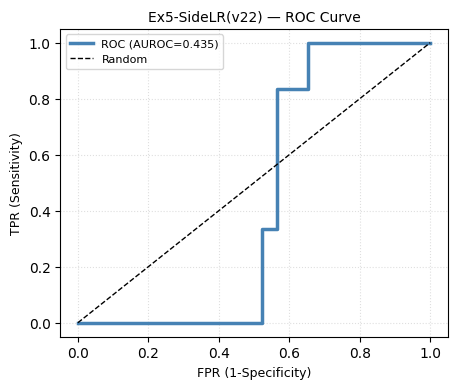

  per-side Platt calibration (v22):
    side=left  a=+0.440 b=-0.624 | side OOF AUROC=0.633 (n=54)
    side=right a=+0.488 b=+0.247 | side OOF AUROC=0.623 (n=51)
  OOF AUROC(flawed) pooled=0.642 [PASS] | P(flawed): correct=0.454 flawed=0.519
  macro-AUROC (within-person): 0.674

  [Ex5-SideLR(v22)] OOF-Platt calibrated test report
{'accuracy': 0.3448, 'balanced_acc': 0.4022, 'precision': 0.1579, 'recall': 0.5, 'sensitivity': 0.5, 'specificity': 0.3043, 'f1': 0.24, 'f2': 0.3488, 'mcc': -0.1667, 'auroc': 0.3188, 'tp': 3, 'tn': 7, 'fp': 16, 'fn': 3}

  [Ex5-SideLR(v22)-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     3 ( 50.0%)       3 ( 50.0%)
  True FLAWED:     16 ( 69.6%)       7 ( 30.4%)


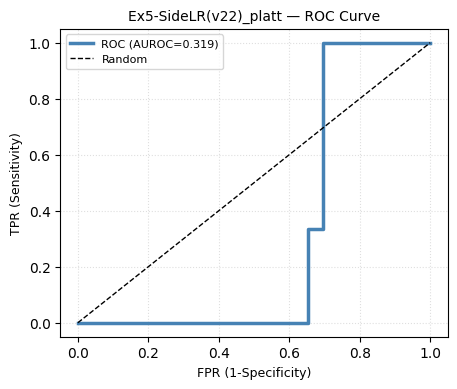


  [Ex5-SideLR(v22)] OOF-quantile cut report (flag_rate=30%, t=0.515)
{'accuracy': 0.3793, 'balanced_acc': 0.4855, 'precision': 0.2, 'recall': 0.6667, 'sensitivity': 0.6667, 'specificity': 0.3043, 'f1': 0.3077, 'f2': 0.4545, 'mcc': -0.0254, 'auroc': 0.3188, 'tp': 4, 'tn': 7, 'fp': 16, 'fn': 2}

  [Ex5-SideLR(v22)-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     4 ( 66.7%)       2 ( 33.3%)
  True FLAWED:     16 ( 69.6%)       7 ( 30.4%)

  [Ex5-SideLR(v22)] ERA cut report (v22 MCC-graded sweep, floor=0.45, t=0.540, floor_ok=True)
{'accuracy': 0.4483, 'balanced_acc': 0.6522, 'precision': 0.2727, 'recall': 1.0, 'sensitivity': 1.0, 'specificity': 0.3043, 'f1': 0.4286, 'f2': 0.6522, 'mcc': 0.2881, 'auroc': 0.3188, 'tp': 6, 'tn': 7, 'fp': 16, 'fn': 0}

  [Ex5-SideLR(v22)-ERAcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     6 (100.0%)       0 (  0.0%)
  True FLAWED:     16 ( 69.6%)       7 ( 30.4%)
worst t

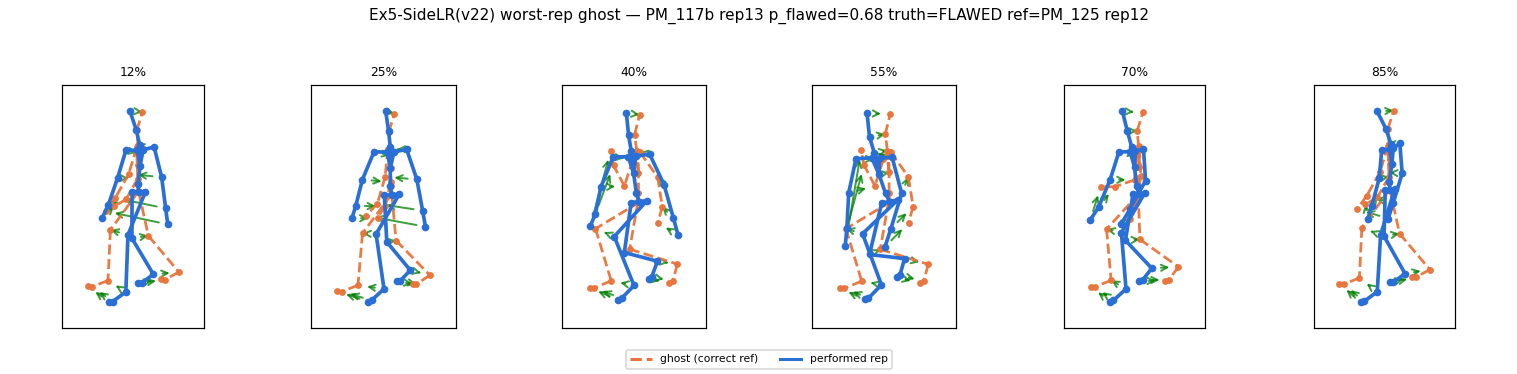

In [ ]:
sidelr_bundle = run_experiment(SideLRSpec(), feat_train, feat_test)

## BackLegLR

In [ ]:
E3_C5 = 7.114476009343421      # frozen (best_configs.json Ex5 params.C)

class BackLegLRSpec(ArchSpec):
    name = "Ex5-BackLegLR(E3)"
    supervised = True
    frozen = True
    min_precision = 0.45

    def search_space(self, trial):
        return dict(C=E3_C5)

    def _mat(self, rows):
        return np.stack([r["bl8"] for r in rows])

    def build(self, rows, p, seed):
        X = self._mat(rows)
        y = np.array([1 - r["label"] for r in rows], int)       # flawed = 1
        return Pipeline([("sc", StandardScaler()),
                         ("m", LogisticRegression(C=p["C"], max_iter=5000, random_state=seed))]
                        ).fit(X, y)

    def score_rows(self, model, rows):
        # model targets FLAWED directly (y = 1−label) -> [:, 1] is already P(flawed)
        return model.predict_proba(self._mat(rows))[:, 1]

    def ship_scores(self, model, rows):
        return self.score_rows(model, rows)

[I 2026-10-23 13:05:54,196] A new study created in memory with name: no-name-4c557c42-0de1-4065-ba7c-0c36fa03afb4



======== Ex5-BackLegLR(E3) ========
  optuna inner split: train reps=74 val reps=31 (person-disjoint: 5/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-23 13:05:54,260] Trial 0 finished with value: -0.037102062762251364 and parameters: {}. Best is trial 0 with value: -0.037102062762251364.
[I 2026-10-23 13:05:54,327] Trial 1 finished with value: -0.037102062762251364 and parameters: {}. Best is trial 0 with value: -0.037102062762251364.
[I 2026-10-23 13:05:54,379] Trial 2 finished with value: -0.037102062762251364 and parameters: {}. Best is trial 0 with value: -0.037102062762251364.
[I 2026-10-23 13:05:54,411] Trial 3 finished with value: -0.037102062762251364 and parameters: {}. Best is trial 0 with value: -0.037102062762251364.
[I 2026-10-23 13:05:54,441] Trial 4 finished with value: -0.037102062762251364 and parameters: {}. Best is trial 0 with value: -0.037102062762251364.
[I 2026-10-23 13:05:54,467] Trial 5 finished with value: -0.037102062762251364 and parameters: {}. Best is trial 0 with value: -0.037102062762251364.
[I 2026-10-23 13:05:54,491] Trial 6 finished with value: -0.037102062762251364 and parameters: {}. B

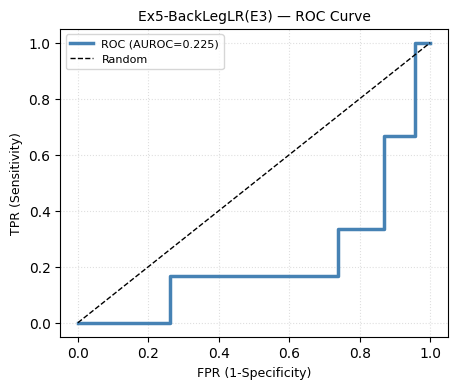

  Platt a=2.352 b=-1.342 | OOF AUROC(flawed)=0.781 [PASS] | P(flawed): correct=0.388 flawed=0.589

  [Ex5-BackLegLR(E3)] OOF-Platt calibrated test report
{'accuracy': 0.4828, 'balanced_acc': 0.3659, 'precision': 0.0909, 'recall': 0.1667, 'sensitivity': 0.1667, 'specificity': 0.5652, 'f1': 0.1176, 'f2': 0.1429, 'mcc': -0.2238, 'auroc': 0.2246, 'tp': 1, 'tn': 13, 'fp': 10, 'fn': 5}

  [Ex5-BackLegLR(E3)-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     1 ( 16.7%)       5 ( 83.3%)
  True FLAWED:     10 ( 43.5%)      13 ( 56.5%)


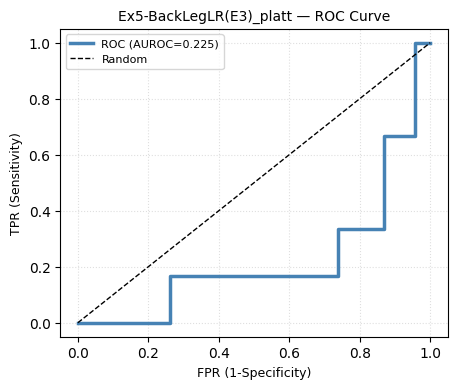


  [Ex5-BackLegLR(E3)] OOF-quantile cut report (flag_rate=30%, t=0.725)
{'accuracy': 0.2414, 'balanced_acc': 0.5217, 'precision': 0.2143, 'recall': 1.0, 'sensitivity': 1.0, 'specificity': 0.0435, 'f1': 0.3529, 'f2': 0.5769, 'mcc': 0.0965, 'auroc': 0.2246, 'tp': 6, 'tn': 1, 'fp': 22, 'fn': 0}

  [Ex5-BackLegLR(E3)-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     6 (100.0%)       0 (  0.0%)
  True FLAWED:     22 ( 95.7%)       1 (  4.3%)

  [Ex5-BackLegLR(E3)] ERA cut report (v22 MCC-graded sweep, floor=0.45, t=0.720, floor_ok=False)
{'accuracy': 0.2414, 'balanced_acc': 0.5217, 'precision': 0.2143, 'recall': 1.0, 'sensitivity': 1.0, 'specificity': 0.0435, 'f1': 0.3529, 'f2': 0.5769, 'mcc': 0.0965, 'auroc': 0.2246, 'tp': 6, 'tn': 1, 'fp': 22, 'fn': 0}

  [Ex5-BackLegLR(E3)-ERAcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     6 (100.0%)       0 (  0.0%)
  True FLAWED:     22 ( 95.7%)       1 (  4.3%)
wo

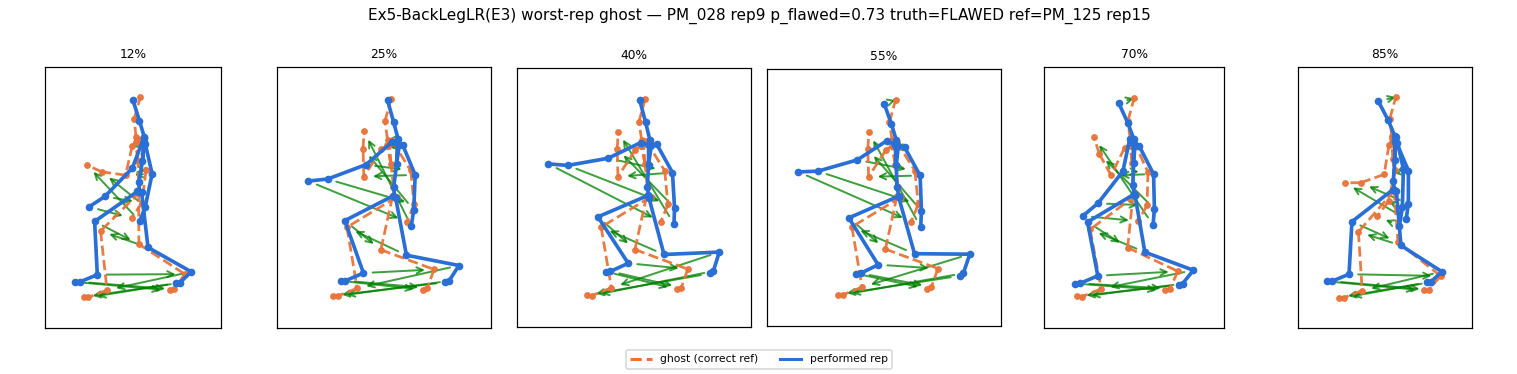

In [ ]:
backleglr_bundle = run_experiment(BackLegLRSpec(), feat_train, feat_test)

## MaskedANN

In [ ]:
import torch
import torch.nn as nn

E1_T = 60                                     # Ex5 hybrid best target_frames (E1 v5)

# E1 v5 Ex5 mask: Spine/Hips (0,1,2) + Legs/Feet (16–25) joints + proxies (52,53)
EX5_JOINTS = [0, 1, 2] + list(range(16, 26))
MASK54 = np.array(sorted([d for j in EX5_JOINTS for d in (2 * j, 2 * j + 1)] + [52, 53]))

def e1_normalize(seqT):
    """E1 `normalize_spatial_root_relative`: per-frame pelvis centring + STATIC
    frame-0 torso scale (Neck−Hips on frame 0)."""
    pelvis = seqT[:, JN["Hips"], :]
    ctr = seqT - pelvis[:, None, :]
    torso0 = np.linalg.norm(ctr[0, JN["Neck"], :] - ctr[0, JN["Hips"], :])
    return ctr / max(float(torso0), 1e-6)

def ann_super(row):
    """E1 v5 `extract_super_features` on the E1-normalized 60-frame template: (60,54)."""
    seq60 = resample_pose(row["tpl_raw"], E1_T)
    nrm = e1_normalize(seq60)
    coords = nrm.reshape(nrm.shape[0], -1)                                   # (T,52)
    knee = np.linalg.norm(nrm[:, JN["LeftLeg"], :] - nrm[:, JN["RightLeg"], :], axis=-1)
    depth = np.abs(nrm[:, [JN["LeftFoot"], JN["RightFoot"]], 1]).mean(axis=1)
    return np.concatenate([coords, knee[:, None], depth[:, None]], axis=1)   # (T,54)

In [ ]:
class AnnAE(nn.Module):
    def __init__(self, units, layers, latent, in_dim=54):
        super().__init__()
        enc = []
        for k in range(layers):
            enc.append(nn.Linear(units if k else in_dim, units))
            enc.append(nn.ReLU())
        enc += [nn.Linear(units, latent)]
        self.enc = nn.Sequential(*enc)
        dec = []
        dlat = latent
        for k in range(layers):
            dec += [nn.Linear(dlat, units), nn.ReLU()]
            dlat = units
        dec += [nn.Linear(units, in_dim)]
        self.dec = nn.Sequential(*dec)

    def forward(self, x):
        return self.dec(self.enc(x))

class MaskedANNRef:
    """E1-v4/v5 style: ANATOMICALLY MASKED reconstruction (Ex5 = spine+legs
    dims), masked-only Huber loss, trains on CORRECT rows (unsupervised)."""
    def __init__(self, p):
        self.p = p

    def fit(self, rows, p):
        set_seed(SEED)
        torch.manual_seed(SEED)
        xs = np.stack([ann_super(r) for r in rows])                 # (N,T,54)
        self.mu = xs.reshape(-1, xs.shape[-1]).mean(0)
        self.sd = np.maximum(xs.reshape(-1, xs.shape[-1]).std(0), 1e-8)
        X = torch.tensor((xs - self.mu) / self.sd, dtype=torch.float32)
        mask = torch.tensor(MASK54, dtype=torch.long)
        net = AnnAE(p["units"], p["layers"], p["latent"])
        opt = torch.optim.Adam(net.parameters(), lr=p["lr"])
        lossf = nn.HuberLoss(reduction="none")
        for _ in range(int(p["epochs"])):
            net.train()
            for i in range(0, len(X), 16):                # E1 Ex5 best batch_size 16
                xb = X[i:i + 16]
                opt.zero_grad()
                err = lossf(net(xb), xb)[:, :, mask]
                loss = err.mean()
                loss.backward()
                opt.step()
        self.net = net.eval()
        self.mask = mask
        return self

    def score_rows(self, rows):
        xs = np.stack([ann_super(r) for r in rows])
        X = torch.tensor((xs - self.mu) / self.sd, dtype=torch.float32)
        with torch.no_grad():
            rec = self.net(X)
        err = nn.functional.huber_loss(rec, X, reduction="none")
        return err[:, :, self.mask].mean(dim=(1, 2)).numpy().astype(np.float64)  # higher=flawed

class MaskedANNSpec(ArchSpec):
    name = "Ex5-MaskedANN-E1"
    supervised = False

    def search_space(self, trial):
        return dict(
            units=trial.suggest_categorical("units", [64, 96, 128, 192]),
            layers=trial.suggest_int("layers", 1, 3),        # E1 Ex5 best ann_layers=1
            latent=trial.suggest_categorical("latent", [8, 16, 24]),
            lr=trial.suggest_float("lr", 1e-4, 3e-3, log=True),
            epochs=trial.suggest_categorical("epochs", [60, 160]),
            q=trial.suggest_float("q", 50.0, 95.0))

    def build(self, rows, p, seed):
        return MaskedANNRef(p).fit(rows, p)

    def score_rows(self, model, rows):
        return model.score_rows(rows)

[I 2026-10-23 13:06:05,890] A new study created in memory with name: no-name-99e1092a-b827-49aa-a18a-30cdaa9642bd



======== Ex5-MaskedANN-E1 ========
  optuna inner split: train reps=74 val reps=31 (person-disjoint: 5/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-23 13:06:17,919] Trial 0 finished with value: 0.5291666666666667 and parameters: {'units': 96, 'layers': 1, 'latent': 24, 'lr': 0.0007725378389307352, 'epochs': 60, 'q': 93.64594334728974}. Best is trial 0 with value: 0.5291666666666667.
[I 2026-10-23 13:06:19,036] Trial 1 finished with value: 0.5583333333333333 and parameters: {'units': 64, 'layers': 1, 'latent': 8, 'lr': 0.0008012737503998541, 'epochs': 160, 'q': 66.48628294821613}. Best is trial 1 with value: 0.5583333333333333.
[I 2026-10-23 13:06:21,017] Trial 2 finished with value: 0.5625 and parameters: {'units': 96, 'layers': 2, 'latent': 16, 'lr': 0.00012476394272569445, 'epochs': 160, 'q': 86.37788066524075}. Best is trial 2 with value: 0.5625.
[I 2026-10-23 13:06:21,609] Trial 3 finished with value: 0.42083333333333334 and parameters: {'units': 128, 'layers': 1, 'latent': 24, 'lr': 0.00024112898115291975, 'epochs': 60, 'q': 73.40306095300149}. Best is trial 2 with value: 0.5625.
[I 2026-10-23 13:06:23,246] Trial 4

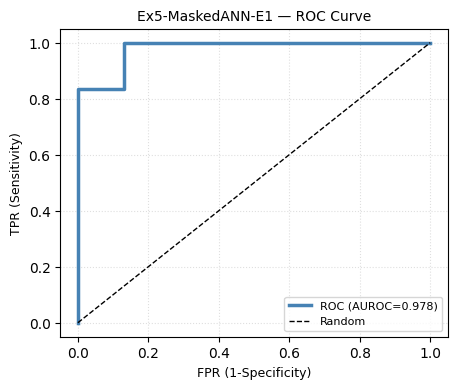

  Platt a=1.000 b=0.000 | OOF AUROC(flawed)=0.523 [PASS] | P(flawed): correct=0.271 flawed=0.277

  [Ex5-MaskedANN-E1] OOF-Platt calibrated test report
{'accuracy': 0.2069, 'balanced_acc': 0.5, 'precision': 0.2069, 'recall': 1.0, 'sensitivity': 1.0, 'specificity': 0.0, 'f1': 0.3429, 'f2': 0.566, 'mcc': 0.0, 'auroc': 0.9783, 'tp': 6, 'tn': 0, 'fp': 23, 'fn': 0}

  [Ex5-MaskedANN-E1-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     6 (100.0%)       0 (  0.0%)
  True FLAWED:     23 (100.0%)       0 (  0.0%)


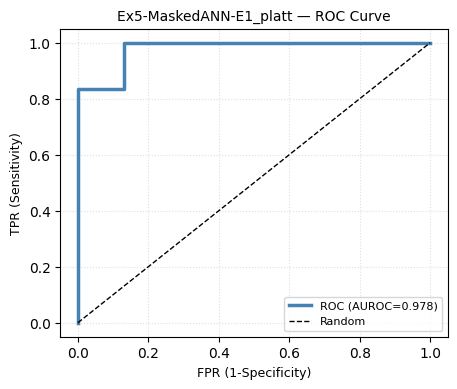


  [Ex5-MaskedANN-E1] OOF-quantile cut report (flag_rate=30%, t=0.330)
{'accuracy': 0.2069, 'balanced_acc': 0.5, 'precision': 0.2069, 'recall': 1.0, 'sensitivity': 1.0, 'specificity': 0.0, 'f1': 0.3429, 'f2': 0.566, 'mcc': 0.0, 'auroc': 0.9783, 'tp': 6, 'tn': 0, 'fp': 23, 'fn': 0}

  [Ex5-MaskedANN-E1-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     6 (100.0%)       0 (  0.0%)
  True FLAWED:     23 (100.0%)       0 (  0.0%)
worst test rep: PM_028 rep18 label=0 p_flawed=0.078 | ghost ref = PM_042 rep16 (front leg left→left, phase-synced panels)
    cue: front knee angle: 140.90 (reference correct reps: median 125.82, typical 117.51 to 130.20); also back knee angle sev 0.60, lateral pelvic sway sev 0.52, back-leg shin verticality sev 0.69
      • [above] Sink the back knee lower toward the floor. (sev 0.2)


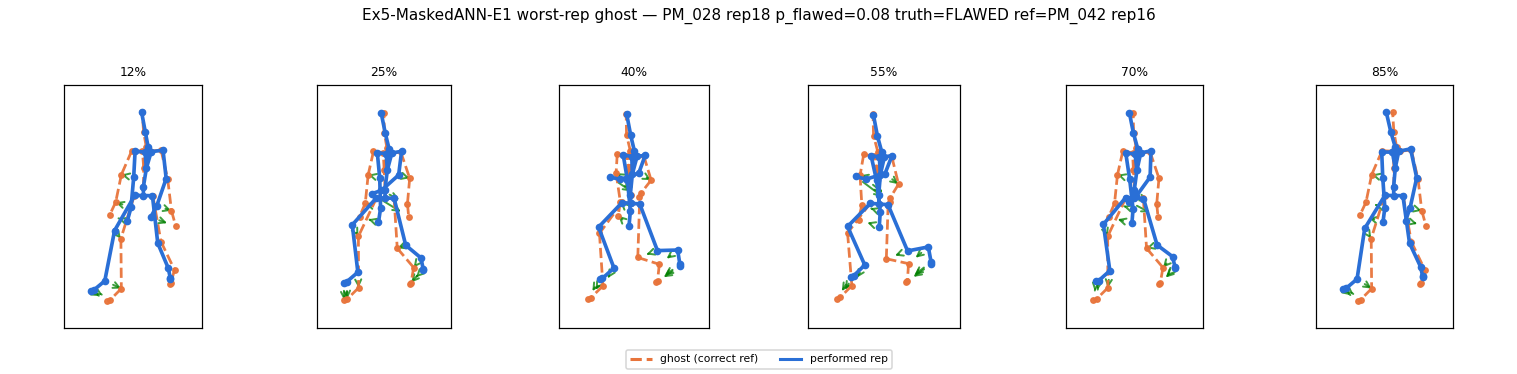

In [ ]:
maskedann_bundle = run_experiment(MaskedANNSpec(), feat_train, feat_test)